# GEDI processor walkthrough

This notebook queries native GEDI shots and prepares them for integration with TLS, ALS, and BIOMASS products. `GEDIProvider` handles remote access; `GEDIProcessor` handles validation, filtering, derived RH metrics, reprojection, sampling, and interface conversion.

Install the required extras with:

```bash
python -m pip install -e '.[gedi,examples]'
```

In [4]:
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box

from tomo_canopy.processors import GEDIProcessor

## Query configuration

The example uses a small WGS84 region in southwestern Ghana and projects results into UTM zone 30N. Confirm the appropriate target CRS for your study site.

In [5]:
BBOX = (-2.70, 5.10, -2.50, 5.30)  # west, south, east, north
START_TIME = "2019-01-01"
END_TIME = "2024-07-25"
TARGET_CRS = "EPSG:32630"
VARIABLES = ["agbd", "rh"]

region = gpd.GeoDataFrame(
    {"name": ["example_roi"]},
    geometry=[box(*BBOX)],
    crs="EPSG:4326",
)

## Query and validate GEDI shots

`open()` delegates the query to `GEDIProvider` and validates the returned shot schema. An empty query remains a valid dataset so optional GEDI coverage does not break a multimodal workflow.

In [6]:
processor = GEDIProcessor()
shots = processor.open(
    region,
    variables=VARIABLES,
    start_time=START_TIME,
    end_time=END_TIME,
)
processor.validate(shots, require_crs=True)
shot_count = shots.sizes.get("shot_number", 0)
print(f"Queried shots: {shot_count:,}")
shots

Queried shots: 21,234


<xarray.Dataset> Size: 10MB
Dimensions:         (shot_number: 21234, profile_points: 101)
Coordinates:
  * shot_number     (shot_number) uint64 170kB 308180000300297325 ... 3078000...
    latitude        (shot_number) float64 170kB 5.107 5.106 5.1 ... 5.11 5.109
    longitude       (shot_number) float64 170kB -2.679 -2.679 ... -2.514 -2.514
    time            (shot_number) datetime64[ns] 170kB 2024-05-22 ... 2019-06-29
    x               (shot_number) float64 170kB -2.679 -2.679 ... -2.514 -2.514
    y               (shot_number) float64 170kB 5.107 5.106 5.1 ... 5.11 5.109
  * profile_points  (profile_points) int16 202B 0 1 2 3 4 5 ... 96 97 98 99 100
Data variables:
    agbd            (shot_number) float32 85kB 51.77 28.68 40.94 ... 126.2 73.8
    rh              (shot_number, profile_points) float32 9MB -3.31 ... 15.17
Attributes:
    source:               gedidb
    modality:             gedi
    geometry_type:        point_cloud
    crs:                  EPSG:4326
    storage_type:         s3
    query_type:           bounding_box
    requested_variables:  ['agbd', 'rh']
    s3_bucket:            dog-ext.gedidb.gedi-l2-l4-v002.0
    query_start_time:     2019-01-01
    query_end_time:       2024-07-25

## Filter measurements and derive RH98

A shot is retained when all requested variables contain at least one valid value. For profile variables, validity is evaluated across the profile dimension. `add_rh_metric()` selects the nearest available percentile label.

In [7]:
processed = shots
if shot_count:
    processed = processor.filter_valid(
        processed, variables=["agbd", "rh"], how="any"
    )
    processed = processor.add_rh_metric(processed, percentile=98)

print(f"Valid shots: {processed.sizes.get('shot_number', 0):,}")
processed

Valid shots: 21,234


<xarray.Dataset> Size: 10MB
Dimensions:         (shot_number: 21234, profile_points: 101)
Coordinates:
  * shot_number     (shot_number) uint64 170kB 308180000300297325 ... 3078000...
    latitude        (shot_number) float64 170kB 5.107 5.106 5.1 ... 5.11 5.109
    longitude       (shot_number) float64 170kB -2.679 -2.679 ... -2.514 -2.514
    time            (shot_number) datetime64[ns] 170kB 2024-05-22 ... 2019-06-29
    x               (shot_number) float64 170kB -2.679 -2.679 ... -2.514 -2.514
    y               (shot_number) float64 170kB 5.107 5.106 5.1 ... 5.11 5.109
  * profile_points  (profile_points) int16 202B 0 1 2 3 4 5 ... 96 97 98 99 100
Data variables:
    agbd            (shot_number) float32 85kB 51.77 28.68 40.94 ... 126.2 73.8
    rh              (shot_number, profile_points) float32 9MB -3.31 ... 15.17
    rh98            (shot_number) float32 85kB 12.29 8.9 14.72 ... 19.4 14.19
Attributes:
    source:               gedidb
    modality:             gedi
    geometry_type:        point_cloud
    crs:                  EPSG:4326
    storage_type:         s3
    query_type:           bounding_box
    requested_variables:  ['agbd', 'rh']
    s3_bucket:            dog-ext.gedidb.gedi-l2-l4-v002.0
    query_start_time:     2019-01-01
    query_end_time:       2024-07-25
    validity_filter:      any
    validity_variables:   ['agbd', 'rh']

## Reproject and inspect spatial bounds

GEDI coordinates arrive as WGS84 longitude and latitude. Reprojection creates metric `x` and `y` coordinates while preserving the original geographic coordinates.

In [8]:
projected = None
bounds = None
if processed.sizes.get("shot_number", 0):
    projected = processor.reproject(processed, target_crs=TARGET_CRS)
    bounds = processor.bounds(projected)
    print(bounds)
else:
    print("No valid shots to reproject.")

<xarray.Dataset> Size: 40B
Dimensions:  (axis: 2)
Coordinates:
  * axis     (axis) <U1 8B 'x' 'y'
Data variables:
    minimum  (axis) float64 16B 5.332e+05 5.637e+05
    maximum  (axis) float64 16B 5.554e+05 5.858e+05
Attributes:
    crs:      EPSG:32630


## Local coordinates and reproducible sampling

Local metric coordinates are useful for joint visualization with TLS. Sampling limits display cost while retaining all variables for the selected shots.

In [9]:
local = None
preview = None
if projected is not None:
    local = processor.to_local_coordinates(projected)
    preview = processor.sample_shots(local, count=5_000, seed=42)
    print(f"Preview shots: {preview.sizes['shot_number']:,}")
    print(
        "Global origin:",
        local.attrs["coordinate_origin_x"],
        local.attrs["coordinate_origin_y"],
    )

Preview shots: 5,000
Global origin: 533244.7091374237 563731.1858465734


## Plot processed shots

The processor returns Xarray datasets, so variables can be plotted directly or passed to the visualization module later.

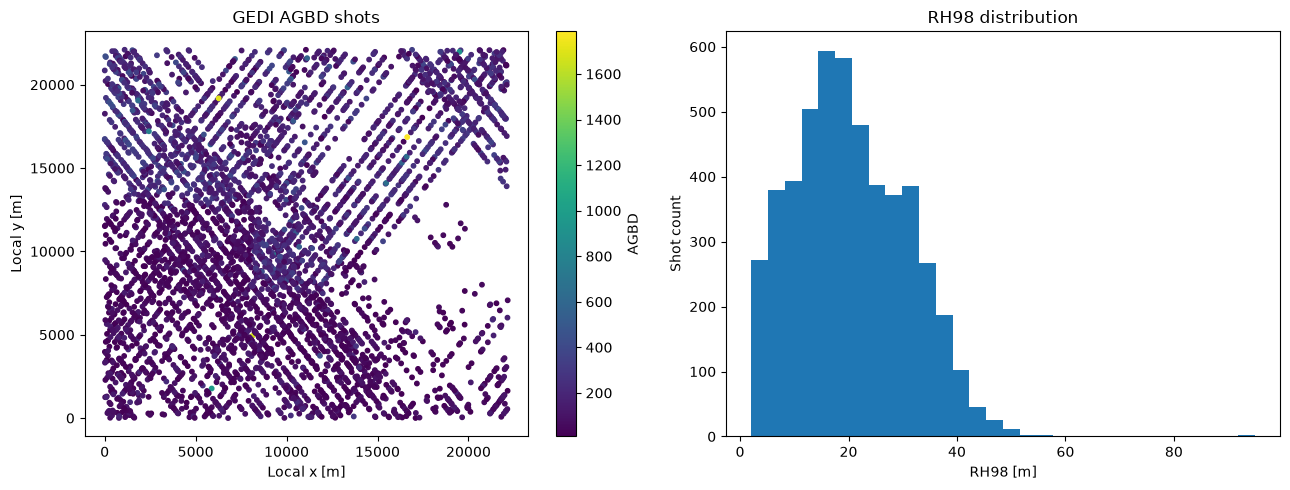

In [10]:
if preview is not None and preview.sizes["shot_number"]:
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    locations = axes[0].scatter(
        preview.x,
        preview.y,
        c=preview.agbd,
        s=10,
        cmap="viridis",
    )
    axes[0].set(
        xlabel="Local x [m]",
        ylabel="Local y [m]",
        title="GEDI AGBD shots",
    )
    fig.colorbar(locations, ax=axes[0], label="AGBD")

    axes[1].hist(preview.rh98.dropna("shot_number"), bins=30)
    axes[1].set(xlabel="RH98 [m]", ylabel="Shot count", title="RH98 distribution")
    plt.tight_layout()
    plt.show()
else:
    print("No processed GEDI shots are available to plot.")

## Create a shared-interface layer

The projected native shots can be wrapped as a `DataLayer`. They are not added directly to a `DataCube`: the future GEDI cube generator must first aggregate the irregular footprints onto its shared `GridSpec`.

In [11]:
gedi_layer = None
if projected is not None:
    gedi_layer = processor.to_data_layer(projected, name="gedi_shots")
    print("Layer name:", gedi_layer.name)
    print("Modality:", gedi_layer.modality)
    print("Geometry:", gedi_layer.geometry)
    print("CRS:", gedi_layer.crs)

Layer name: gedi_shots
Modality: gedi
Geometry: point_cloud
CRS: EPSG:32630
